# Prob 1

## Part d

In [42]:
import open3d as o3d
import numpy as np
from scipy.spatial.transform import Rotation

pcd_gt = o3d.io.read_point_cloud("ground_truth.ply")
pcd_noisy = o3d.io.read_point_cloud("transformed_associated.ply")

r = np.asarray(pcd_gt.points)
r_hat = np.asarray(pcd_noisy.points)

In [43]:
N = len(r)

# center
r_c = np.mean(r, axis=0)
r_hat_c = np.mean(r_hat, axis=0)

# center the point clouds
r_bar = r - r_c
r_hat_bar = r_hat - r_hat_c

# Run part (b)/(c)
H = r_hat_bar.T @ r_bar
U, S, Vt = np.linalg.svd(H)
R = Vt.T @ U.T

# From part (a)
tau = r_c - R @ r_hat_c

In [44]:
# print(r_hat.shape)

In [45]:
# Align other cloud (r_hat)
# Dumb numpy stuff to get this to work vector-wise
r_transformed = (R @ r_hat.T).T

# part (a)
e = r_transformed - r + tau
loss = np.mean(np.sum(e**2, axis=1))

In [46]:
print(f"Optimal translation : {tau}")
print(f"Optimal rotation:\n{R}")
print(f"Loss J(R, tau): {loss}")

Optimal translation : [0.51769478 0.57728611 0.50401143]
Optimal rotation:
[[-0.30702737 -0.9514257   0.02287657]
 [-0.89566072  0.28073815 -0.34493183]
 [ 0.32175468 -0.12639316 -0.93834892]]
Loss J(R, tau): 0.007494166321482214


## Part e

In [47]:
gt_pose = np.loadtxt("gt_pose.csv", delimiter=",", skiprows=1)

qx, qy, qz, qw, px, py, pz = gt_pose
rot_truth = Rotation.from_quat([qx, qy, qz, qw], scalar_first=False)
position = np.array([px, py, pz])

In [48]:
rot_calc = Rotation.from_matrix(R)
R_err = rot_truth * rot_calc.inv()

# Prob 2

In [49]:
# First, install gtsam
# !pip3 install gtsam

In [50]:
# !pip3 list

In [51]:
# Import standard packages
# For vectorized operations and linear algebra
import numpy as np
# For plotting
import matplotlib.pyplot as plt
# For loading in the CSV data as a proper table (i.e., dataframe)
import pandas as pd

# Import the key packages for gtsam
# The top level package
import gtsam
# As implied, the plotting tools
import gtsam.utils.plot as gtsam_plot
# Convenience methods for landmarks (L) and states (X)
# These need to be reset if defined later
from gtsam.symbol_shorthand import L, X

Now we need to load in the data. Click the folder icon at left. This is your directory. Drag the `robot_history_{num}.csv` files into the panel that appears. You will have to repeat this if you restart the Google Colab session.

In [52]:
# Load in the data as a table

# You will come back to change this at the end
### TODO (Q4.b and Q4.g) ###
# filename = 'robot_history_3.csv'
# filename = 'robot_history_5.csv'
filename = 'robot_history_10.csv'
robot_gt_df = pd.read_csv(filename) # this is GROUND TRUTH (gt)!
running_dataset_3 = True if "3" in filename else False
###

# Data is (time), (x, y, theta), (speed, dtheta), (measurements)
n_time_steps, n_params = robot_gt_df.shape
n_landmarks = (n_params - (1 + 3 + 2)) // 2

print(f"Data contains {n_time_steps} time steps and {n_landmarks} landmarks.\n")
robot_gt_df

Data contains 11 time steps and 12 landmarks.



,# time,x,y,theta,speed,dtheta,range_0,range_1,range_2,range_3,...,bearing_2,bearing_3,bearing_4,bearing_5,bearing_6,bearing_7,bearing_8,bearing_9,bearing_10,bearing_11
0,0.0,0.0,0.0,0.000000,3.0,0.000000,1.414214,1.414214,5.099020,7.071068,...,11.309932,8.130102,NaN,NaN,NaN,NaN,29.744881,38.659808,104.036243,99.462322
1,1.0,3.0,0.0,0.000000,3.0,0.000000,4.123106,4.123106,2.236068,4.123106,...,26.565051,14.036243,8.130102,-6.340192,NaN,29.744881,45.000000,63.434949,135.000000,123.690068
2,2.0,6.0,0.0,0.000000,3.0,0.000000,7.071068,7.071068,1.414214,1.414214,...,135.000000,45.000000,14.036243,-9.462322,45.000000,45.000000,75.963757,104.036243,150.255119,139.398705
3,3.0,9.0,0.0,0.000000,3.0,1.570796,NaN,NaN,4.123106,2.236068,...,165.963757,153.434949,45.000000,-18.434949,63.434949,75.963757,116.565051,135.000000,NaN,NaN
4,4.0,12.0,0.0,1.570796,2.5,0.000000,NaN,NaN,7.071068,5.099020,...,81.869898,78.690068,63.434949,-180.000000,0.000000,26.565051,51.340192,60.255119,NaN,NaN
5,5.0,12.0,2.5,1.570796,2.5,1.570796,NaN,NaN,7.158911,5.220153,...,102.094757,106.699244,126.869898,-180.000000,0.000000,53.130102,73.300756,77.905243,NaN,NaN
6,6.0,12.0,5.0,-3.141593,3.0,0.000000,NaN,NaN,8.062258,6.403124,...,29.744881,38.659808,63.434949,90.000000,-90.000000,26.565051,11.309932,8.130102,NaN,NaN
7,7.0,9.0,5.0,-3.141593,3.0,0.000000,NaN,NaN,5.656854,4.472136,...,45.000000,63.434949,104.036243,116.565051,-161.565051,135.000000,26.565051,14.036243,NaN,NaN
8,8.0,6.0,5.0,-3.141593,3.0,0.000000,9.219544,8.062258,4.123106,4.123106,...,75.963757,104.036243,135.000000,135.000000,-170.537678,165.963757,135.000000,45.000000,8.130102,-8.130102
9,9.0,3.0,5.0,-3.141593,3.0,0.000000,7.211103,5.656854,4.472136,5.656854,...,116.565051,135.000000,150.255119,NaN,-173.659808,171.869898,165.963757,153.434949,14.036243,-14.036243


## Adding noise

The data provided is ground truth. The code below adds the required noise. You can change these, but you should put everything back to the original settings when you submit

In [53]:
## Code to roll out the trajectory

def step_robot_pose(pose_curr: np.ndarray, speed: float, delta_theta: float):
    """
    Take the speed and turn to update the 2D pose.
    """
    # Unpack the pose
    x, y, theta = pose_curr

    # Update the position
    x += speed * np.cos(theta)
    y += speed * np.sin(theta)

    # Update the angle at the END of the step
    theta += delta_theta

    # Wrap the angle to [-pi, pi]
    theta = (theta + np.pi) % (2 * np.pi) - np.pi

    # Pack the pose back up
    return np.array([x, y, theta])

def rollout_robot_pose(pose_start: np.ndarray,
                       speeds: np.ndarray,
                       delta_thetas: np.ndarray,
                       ignore_last: bool = True):
    """
    Take the starting pose and step multiple times to get a roll out from the
    starting pose.
    """
    pose_list = [pose_start]
    pose_curr = pose_start.copy()

    for speed, delta_theta in zip(speeds, delta_thetas):
        pose_curr = step_robot_pose(pose_curr, speed, delta_theta)
        pose_list.append(pose_curr)

    if ignore_last:
        pose_list.pop()

    return np.array(pose_list)

In [54]:
# Create noise models

# For the submission use noise_factor = 1, but you may find it helpful to use
# noise_factor = 1e-3 # for testing your code.
noise_factor = 1

# NUMPY VERSIONS
# Feel free to change the numbers, just be sure to change them back for the
# homework submission.
# We assume "pretty good starting"
PRIOR_NOISE_NUMPY = noise_factor * np.array([0.1, 0.1, np.deg2rad(1)])
# 0.3 units in x and y, and 20 degree error in angle, perhaps from wheel encoder
ODOMETRY_NOISE_NUMPY = noise_factor * np.array([0.3, 0.3, np.deg2rad(20)])
# We assume the LIDAR measurements are a lot cleaner
# 0.01 in x and y, and 0.01 degree error in angle
MEASUREMENT_NOISE_NUMPY =  noise_factor * np.array([0.01, np.deg2rad(0.01)])

# GTSAM versions

PRIOR_NOISE = gtsam.noiseModel.Diagonal.Sigmas(noise_factor * PRIOR_NOISE_NUMPY)
ODOMETRY_NOISE = gtsam.noiseModel.Diagonal.Sigmas(noise_factor * ODOMETRY_NOISE_NUMPY)
MEASUREMENT_NOISE = gtsam.noiseModel.Diagonal.Sigmas(noise_factor * MEASUREMENT_NOISE_NUMPY)

In [55]:
# Make a dataframe but with the noisy data
robot_noisy_df = robot_gt_df.copy()

# The random seed is for sanity, to make sure you can run the notebook again
# and get the exact same plots.
np.random.seed(273)
robot_noisy_df["speed"] += np.random.normal(0, ODOMETRY_NOISE_NUMPY[0], n_time_steps)
robot_noisy_df["dtheta"] += np.random.normal(0, ODOMETRY_NOISE_NUMPY[-1], n_time_steps)

# again, we are using "near-perfect initialization" or "relative to initialization"
# So, no noise is added to the initial pose
inital_pose = robot_gt_df[["x", "y", "theta"]].iloc[0].to_numpy()
robot_noisy_df[["x", "y", "theta"]] = rollout_robot_pose(
    inital_pose, robot_noisy_df["speed"], robot_noisy_df["dtheta"])

# add noise to the measurements
# Loop through the landmarks for range and bearing
for l_ind in range(n_landmarks):
    robot_gt_df[f"range_{l_ind}"] += np.random.normal(0, MEASUREMENT_NOISE_NUMPY[0], n_time_steps)
    robot_gt_df[f"bearing_{l_ind}"] += np.random.normal(0, MEASUREMENT_NOISE_NUMPY[1], n_time_steps)

robot_noisy_df

,# time,x,y,theta,speed,dtheta,range_0,range_1,range_2,range_3,...,bearing_2,bearing_3,bearing_4,bearing_5,bearing_6,bearing_7,bearing_8,bearing_9,bearing_10,bearing_11
0,0.0,0.000000,0.000000,0.000000,3.254924,-0.070605,1.414214,1.414214,5.099020,7.071068,...,11.309932,8.130102,NaN,NaN,NaN,NaN,29.744881,38.659808,104.036243,99.462322
1,1.0,3.254924,0.000000,-0.070605,3.008145,-0.210278,4.123106,4.123106,2.236068,4.123106,...,26.565051,14.036243,8.130102,-6.340192,NaN,29.744881,45.000000,63.434949,135.000000,123.690068
2,2.0,6.255575,-0.212213,-0.280883,3.222176,0.330512,7.071068,7.071068,1.414214,1.414214,...,135.000000,45.000000,14.036243,-9.462322,45.000000,45.000000,75.963757,104.036243,150.255119,139.398705
3,3.0,9.351478,-1.105413,0.049630,3.310150,2.089231,NaN,NaN,4.123106,2.236068,...,165.963757,153.434949,45.000000,-18.434949,63.434949,75.963757,116.565051,135.000000,NaN,NaN
4,4.0,12.657552,-0.941200,2.138860,2.482692,-0.335601,NaN,NaN,7.071068,5.099020,...,81.869898,78.690068,63.434949,-180.000000,0.000000,26.565051,51.340192,60.255119,NaN,NaN
5,5.0,11.321861,1.151571,1.803259,2.678351,1.677509,NaN,NaN,7.158911,5.220153,...,102.094757,106.699244,126.869898,-180.000000,0.000000,53.130102,73.300756,77.905243,NaN,NaN
6,6.0,10.704836,3.757880,-2.802417,3.001207,-0.221030,NaN,NaN,8.062258,6.403124,...,29.744881,38.659808,63.434949,90.000000,-90.000000,26.565051,11.309932,8.130102,NaN,NaN
7,7.0,7.874610,2.759347,-3.023447,2.853366,0.082388,NaN,NaN,5.656854,4.472136,...,45.000000,63.434949,104.036243,116.565051,-161.565051,135.000000,26.565051,14.036243,NaN,NaN
8,8.0,5.041135,2.423018,-2.941059,2.969787,-0.219678,9.219544,8.062258,4.123106,4.123106,...,75.963757,104.036243,135.000000,135.000000,-170.537678,165.963757,135.000000,45.000000,8.130102,-8.130102
9,9.0,2.130861,1.831459,3.122448,2.694623,0.190524,7.211103,5.656854,4.472136,5.656854,...,116.565051,135.000000,150.255119,NaN,-173.659808,171.869898,165.963757,153.434949,14.036243,-14.036243


## (Q4.b-c) Building the factor graph

In [56]:
# Re-import here so that you can rerun this cell to debug without rerunning
# everything
from gtsam.symbol_shorthand import L, X

# Create an empty nonlinear factor graph
### TODO (Q4.b) ###
graph = gtsam.NonlinearFactorGraph()
###

Xs = [X(i) for i in range(n_time_steps)]
Ls = [L(i) for i in range(n_landmarks)]

# Add a prior factor at the origin to set the origin of the SLAM problem
### TODO (Q4.b) ###
pose0 = gtsam.Pose2(0, 0, 0)
graph.add(gtsam.PriorFactorPose2(Xs[0], pose0, PRIOR_NOISE))

###

# Loop through the noisy data (i.e., `robot_noisy_df`)
# In the loop,
#    get the relative motion with pose_{i} - pose_{i - 1}
#    the measurements are in the noisy data
# Don't forget the loop closure constraint
### TODO (Q4.c) ####
prev_pose = pose0

rel_motion = []

for i,row in robot_noisy_df.iterrows():
    # print(row.keys())
    if i == 0:
        continue

    # Relative motion pose data
    cur_pose = gtsam.Pose2(*row[["x", "y", "theta"]])
    graph.add(gtsam.BetweenFactorPose2(Xs[i-1], Xs[i], prev_pose.between(cur_pose), ODOMETRY_NOISE))
    prev_pose = cur_pose

    for i_l in range(n_landmarks):
        l_range = robot_noisy_df[f"range_{i_l}"][i]
        l_bearing = robot_noisy_df[f"bearing_{i_l}"][i]
        
        if pd.isnull(l_range) or pd.isnull(l_bearing):
            continue
        # print(f"pose {i} landmark {i_l} - bearing: {l_bearing}\n\t     l_range: {l_range}\n\n")
        graph.add(gtsam.BearingRangeFactor2D(Xs[i], Ls[i_l],
            gtsam.Rot2.fromDegrees(l_bearing), l_range, MEASUREMENT_NOISE))

# Loop closure constraint
graph.add(gtsam.BetweenFactorPose2(Xs[2], Xs[8], gtsam.Pose2(0, 5, 180), ODOMETRY_NOISE)) 

###

# Print the factor graph to see all the nodes
### TODO (Q4.c) ####
print(graph)

###

NonlinearFactorGraph: size: 106

Factor 0: PriorFactor on x0
  prior mean:  (0, 0, 0)
  noise model: diagonal sigmas [0.1; 0.1; 0.0174532925];

Factor 1: BetweenFactor(x0,x1)
  measured:  (3.25492435, 0, -0.0706048005)
  noise model: diagonal sigmas [0.3; 0.3; 0.34906585];

Factor 2: BearingRangeFactor
Factor 2:   keys = { x1 l0 }
  noise model: diagonal sigmas [0.01; 0.000174532925];
ExpressionFactor with measurement: bearing : -2.89661399
range  4.12310563

Factor 3: BearingRangeFactor
Factor 3:   keys = { x1 l1 }
  noise model: diagonal sigmas [0.01; 0.000174532925];
ExpressionFactor with measurement: bearing : 2.89661399
range  4.12310563

Factor 4: BearingRangeFactor
Factor 4:   keys = { x1 l2 }
  noise model: diagonal sigmas [0.01; 0.000174532925];
ExpressionFactor with measurement: bearing : 0.463647609
range  2.23606798

Factor 5: BearingRangeFactor
Factor 5:   keys = { x1 l3 }
  noise model: diagonal sigmas [0.01; 0.000174532925];
ExpressionFactor with measurement: bearing : 0

## (Q4.d) Initialize the optimization problem

In [57]:
# Set-up a values data structure for the initial estimate
### TODO (Q4.d) ###
initial_estimate = gtsam.Values()

###

# Set the initial poses from the noisy odometry alone
# Hint, you already have this in `robot_noisy_df`
### TODO (Q4.d) ###

for i,row in robot_noisy_df.iterrows():
    pose = gtsam.Pose2(*row[["x", "y", "theta"]])
    initial_estimate.insert(Xs[i], pose)

###

# Sample random values for the initial landmark positions
# In reality, you would have to estimate these from odometry,
# but to not over-complicate the problem, just use noisy
# ground-truth.
# In reality, the initialization is very important for the
# graph optimization to converge to a good solution!!
l_init_vec = [
    (-1, -1),
    (-1, 1),
    (5, 1),
    (7, 1),
    (10, 1),
    (12, -1),
    (12, 6),
    (10, 4),
    (7, 4),
    (5, 4),
    (-1, 4),
    (-1, 6)
]

observed_landmarks = set()

for l_ind, L_val in enumerate(Ls):
    l_hat = l_init_vec[l_ind]
    point_init = (np.random.normal(l_hat[0], ODOMETRY_NOISE_NUMPY[0]),
                  np.random.normal(l_hat[1], ODOMETRY_NOISE_NUMPY[0]))
    # Add the initial estimates of the landmarks
    ### TODO (Q4.d) ###

    l_range = robot_noisy_df[f"range_{l_ind}"]
    l_bearing = robot_noisy_df[f"bearing_{l_ind}"]

    # print(l_bearing.notna().any())
    was_observed = (
        l_range.notna().any() and
        l_bearing.notna().any()
    )

    # if was_observed:
    #     initial_estimate.insert(...)

    if was_observed:
        print(l_ind)
        landmark = gtsam.Point2(*point_init)
        initial_estimate.insert(L_val, landmark)
        observed_landmarks.add(l_ind)


# Print the initial estimates to verify
### TODO (Q4.d) ###
initial_estimate
###

0
1
2
3
4
5
6
7
8
9
10
11


Values with 23 values:
Value l0: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	-1.04531412;
	-1.21481369
]

Value l1: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	-1.00629039;
	1.17309668
]

Value l2: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	4.5809314;
	0.992908941
]

Value l3: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	6.58246277;
	0.865267077
]

Value l4: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	9.66434412;
	1.08988328
]

Value l5: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	11.5884324;
	-1.3857714
]

Value l6: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	12.4511261;
	5.92072691
]

Value l7: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	9.46084069;
	3.89537827
]

Value l8: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	7.25516174;
	4.41311515
]

Value l9: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	4.81397342;
	3.97336983
]

Value l10: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	-1.36212978;
	3.67352319
]

Value l11: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	-0.498201812;
	5.55854322

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/gtsam/utils/plot.py:179: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "r." (-> marker='.'). The keyword argument will take precedence.
  axes.plot([point[0]], [point[1]], linespec, marker='.', markersize=10)


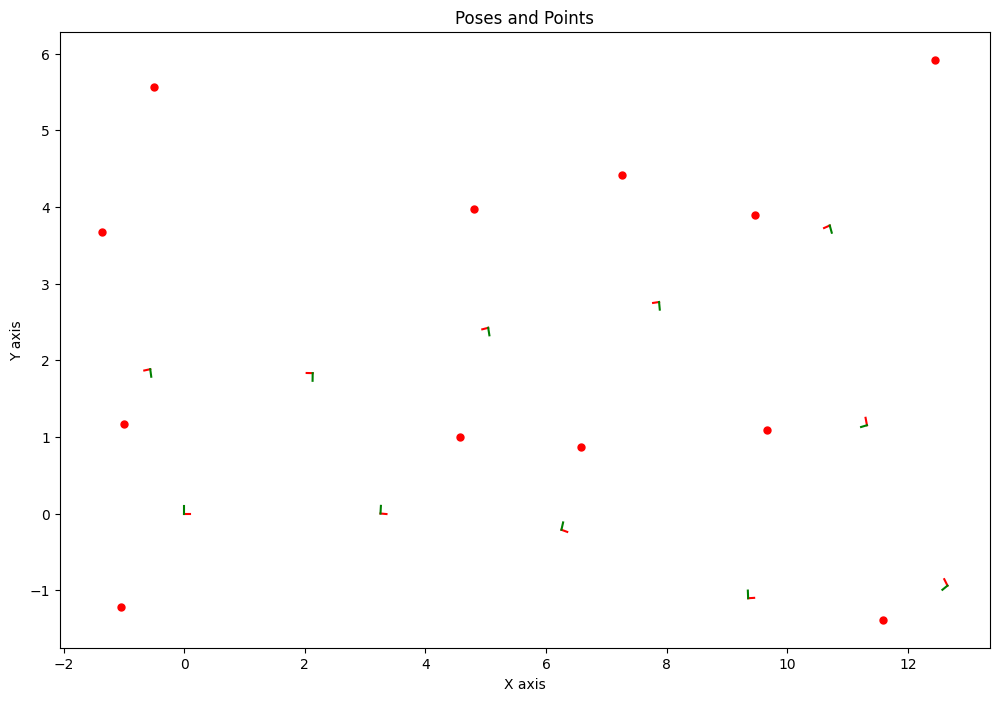

In [58]:
# Plot the initial poses and landmarks.
# For example, for poses, the code is
# gtsam_plot.plot_pose2(
#         fignum: int,
#         pose: Pose2,
#         axis_length: float = 0.1,
#         covariance: np.ndarray = None,
#         axis_labels=("X axis", "Y axis", "Z axis"),
# )
# We do need covariance for this part. The source code is here:
# https://github.com/borglab/gtsam/blob/develop/python/gtsam/utils/plot.py

# Don't forget to use axis equals!


### TODO (Q4.d) ###

fignum = 0
plt.figure(fignum, figsize=(12,8))
# Poses
for i in range(len(Xs)):
    pose = initial_estimate.atPose2(Xs[i])
    gtsam_plot.plot_pose2(fignum, pose)

# Landmarks
# for i in range(len(Ls)):
for i in observed_landmarks:
    # print(observed_landmarks)
    point = initial_estimate.atPoint2(Ls[i])
    gtsam_plot.plot_point2(fignum, point, "r.")

plt.title("Poses and Points")
plt.show()

###

## (Q4.e) Graph Optimization

In [59]:
# We are going to optimize with the Levenberg-Marquardt solver.
# You can definitely consider other options (e.g., Gauss Newton).
# You may be interested in AA 222: Optimization for more about these
# methods. Levenberg-Marquardt has a number of configuration
# parameters, but we will use the defaults. For your projects, you
# might consider tweaking the parameters for tighter convergence.

lm_params = gtsam.LevenbergMarquardtParams()

# for j in range(n_landmarks):
#     key = L(j)
#     if initial_estimate.exists(key) and not graph.exists(key):
#         print(j)
#         initial_estimate.erase(key)

if running_dataset_3:
    initial_estimate.erase(Ls[0])
    initial_estimate.erase(Ls[1])
# initial_estimate.erase(key)

# Fill the optimizer with your graph and initial estimates (in that
# order).
### TODO (Q4.e) ###
optimizer = gtsam.LevenbergMarquardtOptimizer(graph, initial_estimate, lm_params)
result = optimizer.optimize()
###

# Print the results
### TODO (Q4.e) ###
result
###

Values with 23 values:
Value l0: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	-0.805666715;
	-0.715262369
]

Value l1: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	-0.664544176;
	1.27975253
]

Value l2: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	5.32050053;
	0.856384907
]

Value l3: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	7.31551542;
	0.715262361
]

Value l4: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	10.3080378;
	0.503578575
]

Value l5: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	12.1619301;
	-1.63255885
]

Value l6: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	12.655859;
	5.34999328
]

Value l7: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	10.5197216;
	3.49610091
]

Value l8: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	7.52719922;
	3.70778471
]

Value l9: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	5.53218433;
	3.84890724
]

Value l10: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	-0.452860364;
	4.27227488
]

Value l11: (Eigen::Matrix<double, -1, 1, 0, -1, 1>)
[
	-0.311737838;
	6.26

In [60]:
# To understand uncertainty, you need the marginal Gaussian distributions.
# gtsam makes this directly accessible with
# marginals = gtsam.Marginals(graph, result)
# The covariance matrices are in marginals. For example, the covariance
# matrix for X(1) (i.e., Xs[0]) is
# marginals.marginalCovariance(X(1))

# Check that you can print the marginal covariance matrices for both poses
# and landmarks
### TODO (Q4.e) ###

marginals = gtsam.Marginals(graph, result)
# print(marginals.marginalCovariance(X(1)))
# print(marginals.marginalCovariance(L(1)))

###

/var/folders/l4/vmh1rmg52flbd1tpkc0s470c0000gn/T/ipykernel_88975/3857811003.py:47: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


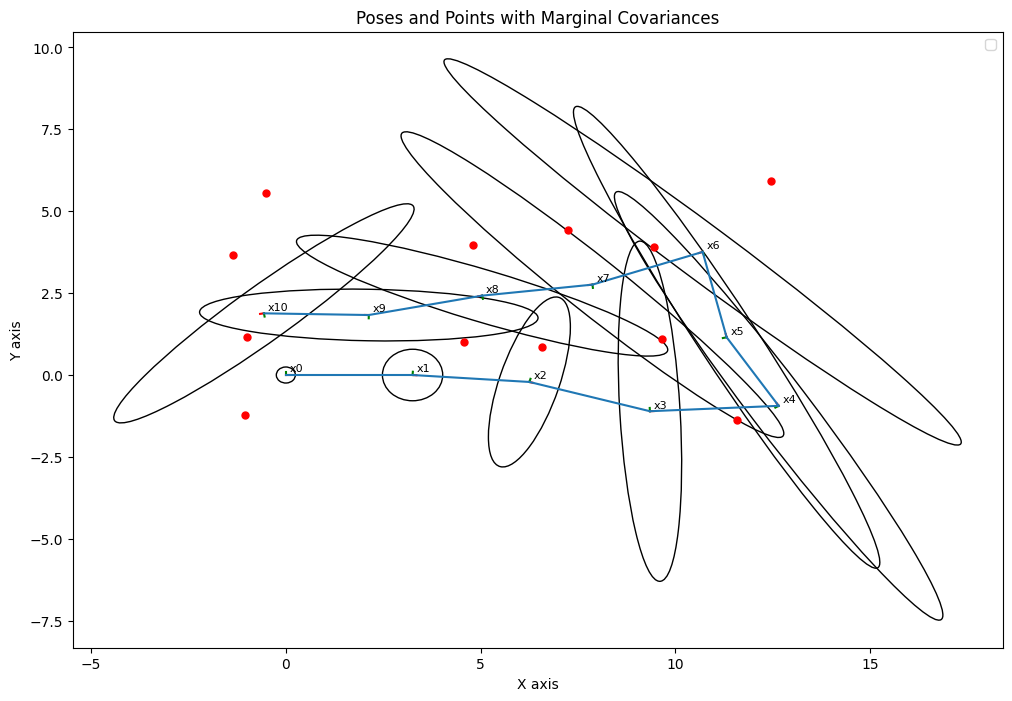

In [61]:
# Now plot the poses and landmarks _with_ covariance ellipses.
### TODO (Q4.e) ###

fignum = 1
plt.figure(fignum, figsize=(12,8))
# Poses
for i in range(len(Xs)):
    pose = initial_estimate.atPose2(Xs[i])
    cov = marginals.marginalCovariance(Xs[i])  # 3x3
    gtsam_plot.plot_pose2(fignum, pose, covariance=cov)
    plt.text(pose.x()+0.1, pose.y()+0.1, f"x{i}", fontsize=8)

# Landmarks
for i in range(len(Ls)):
    if running_dataset_3:
        if i in [0,1]:
            continue
    point = initial_estimate.atPoint2(Ls[i])
    gtsam_plot.plot_point2(fignum, point, "r.")

###

# You may find if helpful to plot line segments connecting poses at
# adjacent time steps to understand what is happening.
# For a given `pose`, use `pose.translation()` to get the translation
# term (i.e., the position)
### TODO (Q4.h) ###

plt.title("Poses and Points with Marginal Covariances")


for i in range(len(Xs) - 1):

    pose_i = initial_estimate.atPose2(Xs[i])
    pose_j = initial_estimate.atPose2(Xs[i+1])

    t_i = pose_i.translation()
    t_j = pose_j.translation()

    x_vals = [t_i[0], t_j[0]]
    y_vals = [t_i[1], t_j[1]]

    # label = "Trajectory" if i == 0 else None
    plt.plot(x_vals, y_vals, "tab:blue", label=None)

    
plt.legend()
plt.show()
###